# DESC 3.0 tutorial: Paul et al. (2015)

This notebook clusters the mouse myeloid progenitor data of Paul et al. (2015) with [DESC](https://github.com/eleozzr/desc) 3.0, the PyTorch version. It repeats the steps of the desc 2.1.1 notebook (`desc_2.1.1_paul.ipynb`) and adds a comparison with the published cell labels.

It runs on a CPU in about a minute. The Paul15 data is downloaded to `./data/paul15` the first time.

To run it yourself from a clone of the repository:

```bash
uv sync --extra cpu
uv run --with jupyter jupyter lab desc_3.0_paul.ipynb
```

In [1]:
import sys
import warnings
warnings.filterwarnings("ignore")  # keep the tutorial output readable

import desc
import numpy as np
import pandas as pd
import scanpy as sc
import torch
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

sc.settings.set_figure_params(dpi=80)
print("python", sys.version.split()[0])
print("desc  ", desc.__version__)
print("torch ", torch.__version__)
print("scanpy", sc.__version__)

python 3.14.3
desc   3.0.0
torch  2.14.1+cpu
scanpy 1.12.4


## Load the data

`celltype2` holds the 19 published clusters (for example `7MEP`) and `celltype` the 10 cell types without the cluster number (`MEP`).

In [2]:
adata = sc.datasets.paul15()
adata.obs["celltype"] = adata.obs["paul15_clusters"].astype(str).str.replace(r"^[0-9]{1,2}", "", regex=True).astype("category")
adata.obs["celltype2"] = adata.obs["paul15_clusters"]
adata

AnnData object with n_obs × n_vars = 2730 × 3451
    obs: 'paul15_clusters', 'celltype', 'celltype2'
    uns: 'iroot'
    layers: None (.X)

## Preprocess

Log-transform, keep the 1,000 most variable genes and scale each gene, clipping at 6 standard deviations. These are the same steps as in the 2.x notebook, written with current scanpy functions.

In [3]:
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=1000, subset=True)
sc.pp.scale(adata, max_value=6)
adata

AnnData object with n_obs × n_vars = 2730 × 1000
    obs: 'paul15_clusters', 'celltype', 'celltype2'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'iroot', 'log1p', 'hvg'
    layers: None (.X)

## Train DESC

The call is the same as in desc 2.x. DESC pretrains a stacked autoencoder, initializes clusters with Louvain at each resolution, and then refines the clusters. `num_Cores=1` makes the run reproducible.

To train on a GPU, set `use_GPU=True` and `GPU_id=0`. Setting `use_GPU=True` without a `GPU_id` keeps training on the CPU.

`desc.train` prints a line for every training epoch. `%%capture` keeps that log out of the notebook, and the next cell prints the summary of the last resolution.

In [4]:
%%capture train_log
adata = desc.train(
    adata,
    dims=[adata.shape[1], 64, 32],
    tol=0.005,
    n_neighbors=10,
    batch_size=256,
    louvain_resolution=[0.8, 1.0],  # a single value such as 1.0 also works
    save_dir="paul_result",
    do_tsne=True,
    learning_rate=200,  # t-SNE learning rate
    use_GPU=False,
    num_Cores=1,
    num_Cores_tsne=4,
    save_encoder_weights=False,
    use_ae_weights=False,
    do_umap=False,
)

In [5]:
log = train_log.stdout
print(log[log.rindex("The final prediction cluster is:"):])

The final prediction cluster is:
0    529
1     97
2    227
3     67
4    476
5    365
6    792
7    115
8     33
9     29
Name: count, dtype: int64
The desc has been trained successfully!!!!!!
The summary of desc model is:
Model: "desc"
___________________________________________________________
Layer (type)                    Output Shape    Param #    
encoder_0 (Dense)               (None, 64)      64064      
encoder_1 (Dense)               (None, 32)      2080       
clustering (ClusteringLayer)    (None, 10)      320        
Total params: 66464
The runtime of (resolution=1.0)is: 1.658902645111084
tsne finished and added X_tsne1.0  into the t-SNE coordinates (adata.obsm)

The run time for all resolution is: 43.10572695732117
After training, the information of adata is:
 AnnData object with n_obs × n_vars = 2730 × 1000
    obs: 'paul15_clusters', 'celltype', 'celltype2', 'desc_0.8', 'desc_1.0'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
  

## Results

For each resolution, DESC adds:

* `adata.obs["desc_<resolution>"]`: the cluster of each cell
* `adata.uns["prob_matrix<resolution>"]`: the probability of each cell belonging to each cluster
* `adata.obsm["X_Embeded_z<resolution>"]`: the low-dimensional representation learned by DESC
* `adata.obsm["X_tsne<resolution>"]`: t-SNE coordinates of that representation, because `do_tsne=True`

The trained networks are saved as PyTorch files in `save_dir`.

In [6]:
import os
sorted(os.listdir("paul_result"))

['ae_weights.pt',
 'autoencoder_model.pt',
 'encoder_model.pt',
 'encoder_weights.pt']

## t-SNE plots

`max.prob` is each cell's highest cluster probability. Low values mark cells that sit between clusters.

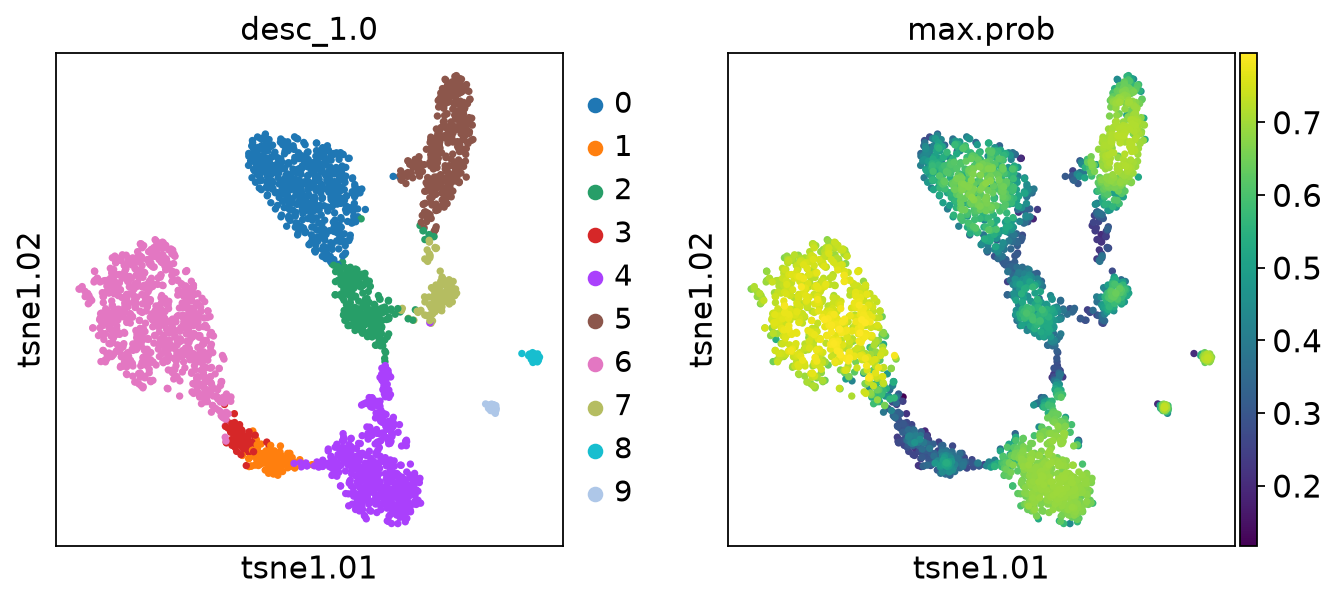

In [7]:
adata.obs["max.prob"] = adata.uns["prob_matrix1.0"].max(1)
sc.pl.embedding(adata, basis="tsne1.0", color=["desc_1.0", "max.prob"])

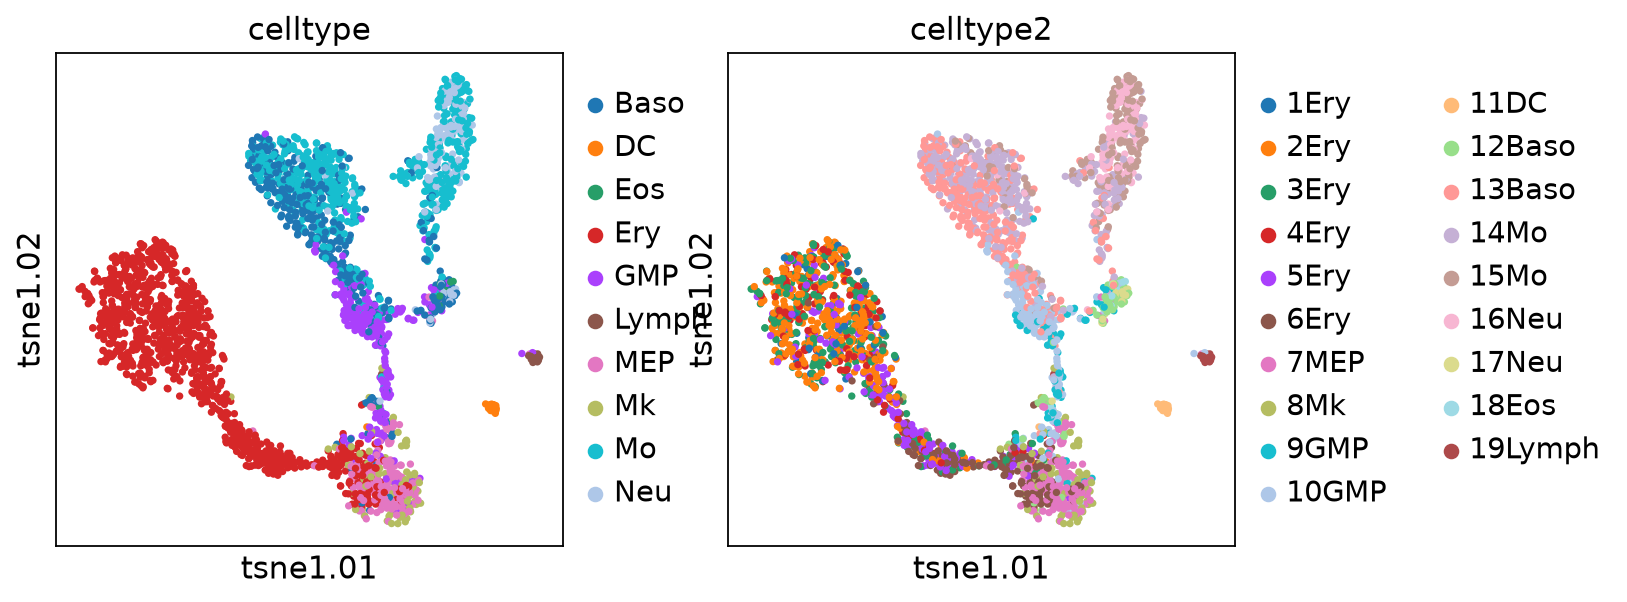

In [8]:
sc.pl.embedding(adata, basis="tsne1.0", color=["celltype", "celltype2"])

## Agreement with the published labels

Adjusted Rand index (ARI) and normalized mutual information (NMI) between the DESC clusters and the published labels. 1 means identical partitions.

In [9]:
rows = []
for res in ["0.8", "1.0"]:
    pred = adata.obs["desc_" + res]
    for name, col in [("19 published clusters", "celltype2"), ("10 cell types", "celltype")]:
        rows.append({"resolution": res, "reference": name, "clusters found": pred.nunique(),
                     "ARI": adjusted_rand_score(adata.obs[col], pred),
                     "NMI": normalized_mutual_info_score(adata.obs[col], pred)})
pd.DataFrame(rows).round(3)

,resolution,reference,clusters found,ARI,NMI
0,0.8,19 published clusters,10,0.343,0.561
1,0.8,10 cell types,10,0.518,0.589
2,1.0,19 published clusters,10,0.330,0.550
3,1.0,10 cell types,10,0.487,0.571


In [10]:
pd.crosstab(adata.obs["celltype"], adata.obs["desc_1.0"])

desc_1.0,0,1,2,3,4,5,6,7,8,9
celltype,,,,,,,,,,
Baso,212,0,69,0,26,10,0,52,0,0
DC,0,0,0,0,1,0,0,0,0,29
Eos,0,0,0,0,2,0,0,7,0,0
Ery,0,96,0,67,141,0,791,0,0,0
GMP,6,0,117,0,74,0,0,17,2,0
Lymph,0,0,0,0,1,0,0,0,30,0
MEP,0,1,0,0,160,0,0,5,1,0
Mk,0,0,0,0,67,0,1,0,0,0
Mo,302,0,39,0,2,202,0,14,0,0


## Save the result

In [11]:
adata.write_h5ad("paul_result/adata_desc.h5ad")

## Differences from the 2.x notebooks

* desc 3.0 runs on PyTorch and Python 3.14 or newer. The `desc.train` arguments are unchanged.
* The weights in `save_dir` are `.pt` files instead of `.h5` files.
* The Louvain initialization uses igraph, because the `louvain` package no longer installs. Cluster counts can differ slightly from 2.x at the same resolution.
* Results are not bit-identical to 2.x, because the random number generators differ. See `benchmarks/tf_parity` in the repository for a side-by-side comparison with desc 2.1.1.

## Reference

Paul F, Arkin Y, Giladi A, Jaitin DA, et al. Transcriptional heterogeneity and lineage commitment in myeloid progenitors. *Cell* 163:1663–1677 (2015).